# AURORA SCORE — Implementación técnica del prototipo (EP5)
**SCY1102 Gestión de Proyectos de Datos · Vertex Financial Group (VFG)**
Integrantes: Marvin Francisconi · Ricardo Illanes · Docente: José Luis Barría

Este notebook es el **entregable funcional** de la Evaluación Parcial N°5. Implementa, en Python, un prototipo de punta a punta del motor de score alternativo:
datos → calidad → preparación → modelo → evaluación → equidad → motor de decisión → latencia → monitoreo de drift.

**Trazabilidad con el plan (WBS de la EP2 / tablero Trello):**

| Sección del notebook | Tarea WBS / tarjeta Trello | Requerimiento |
|---|---|---|
| 1. Datos del piloto | 2.1 Identificación y conexión de fuentes | RF01 |
| 2. Calidad de datos | 2.2 Evaluación de calidad y consistencia | RF02 · RNF06 |
| 3. Preparación | 2.3 Limpieza, integración y transformación | RF02 · RNF04 |
| 4–5. Modelado y evaluación | 3.2 Desarrollo y entrenamiento de modelos ML | RF03 |
| 6. Explicabilidad | 4.2 Evaluación de sesgos y explicabilidad | RF05 · RNF08 |
| 7. Auditoría de equidad | 4.2 Evaluación de sesgos y explicabilidad | RNF08 |
| 8. Motor de decisión | 3.3 Implementación del motor de decisiones | RF04 |
| 9. Latencia | 4.1 Pruebas de rendimiento y escalabilidad | RNF01 |
| 10. Drift | 5.2 Monitoreo y documentación final | RNF07 |
| 11. Artefactos | 5.2 Monitoreo y documentación final | RNF07 |

> **Nota sobre los datos.** El caso es ficticio y no entrega microdatos. Para no bloquear el desarrollo (desviación D1 del informe) se construye un **dataset sintético** que replica la estructura del piloto descrito en el caso: 12.000 créditos en Chile y Perú, mora ≈ 11 % (Tabla 4, Año 1), fuentes alternativas de telecomunicaciones, servicios básicos, billeteras y e-commerce, con los sesgos de representación documentados por VFG. El pipeline es el mismo que se usaría con los datos reales.

In [1]:
import json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier, BaggingClassifier, RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, precision_score, recall_score,
                             f1_score, confusion_matrix, brier_score_loss)
from sklearn.inspection import permutation_importance
import joblib, sklearn

warnings.filterwarnings("ignore")
SEED = 42                      # reproducibilidad (Definition of Done)
rng = np.random.default_rng(SEED)
OUT = Path("outputs"); FIG = OUT / "figs"; DATA = Path("data")
for p in (OUT, FIG, DATA):
    p.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, NARANJO, GRIS, ROJO, VERDE = "#2b5a8a", "#d9822b", "#8a8f98", "#c0392b", "#2e8b57"
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| numpy", np.__version__)

pandas 3.0.5 | scikit-learn 1.9.1 | numpy 2.5.2


## 1. Datos del piloto (WBS 2.1 · RF01)
Se simulan las fuentes que el caso declara, cada una con su granularidad por solicitante:

| Fuente | Variables | Observación del caso |
|---|---|---|
| Telecomunicaciones (3 operadoras) | antigüedad de línea, plan postpago, recarga mensual, regularidad de pago | geolocalización solo por antena |
| Servicios básicos (utilities) | % de cuentas pagadas a tiempo, meses de historial | rezago de 24–72 h → nulos |
| Billeteras y e-commerce | transacciones/mes, compras/mes, ticket, tasa de devoluciones | |
| Redes sociales (opt-in) | antigüedad de cuenta | solo con autorización → muchos nulos |
| App VFG (metadatos) | tiempo de llenado del formulario | **excluida del modelo** (sesgo S5) |
| Proxies sensibles | gama del teléfono, nivel socioeconómico de comuna | **excluidas del modelo** (sesgo S2) |
| Atributos protegidos | género, zona, tramo etario, sector informal | **solo para auditoría**, nunca como predictor |

La variable objetivo `default` = incumplimiento > 30 días. La mora **no** depende directamente del género, zona o edad: depende del comportamiento de pago. Así, cualquier brecha que el modelo produzca entre grupos es atribuible a sesgo de representación o a variables correlacionadas, que es justamente lo que la auditoría del punto 7 debe detectar.

In [2]:
N = 12_000
pais = rng.choice(["Chile", "Peru"], N, p=[0.55, 0.45])
# Sesgo histórico de representación (caso, sección 4): sobrerrepresenta urbanos, hombres y 25-45 años
genero = rng.choice(["M", "F"], N, p=[0.62, 0.38])
zona = rng.choice(["urbana", "rural"], N, p=[0.84, 0.16])
edad = np.clip(np.where(rng.random(N) < 0.70, rng.normal(35, 6, N), rng.normal(45, 15, N)), 18, 78).round()
informal = (rng.random(N) < np.where(genero == "F", 0.42, 0.25)).astype(int)
tramo_edad = pd.cut(edad, [17, 24, 45, 60, 100], labels=["18-24", "25-45", "46-60", "60+"]).astype(str)

ruralf = (zona == "rural").astype(float)
# --- Telecomunicaciones
antig_linea = np.clip(rng.gamma(2.2, 14, N) + (edad - 18) * 0.6, 1, 240).round()
postpago = (rng.random(N) < 0.45 - 0.20 * ruralf - 0.10 * informal).astype(int)
recarga_mes = np.clip(rng.lognormal(2.6, 0.6, N) * (1 - 0.5 * postpago), 0, 300).round(1)
regularidad_telco = np.clip(rng.beta(6, 2, N), 0, 1).round(3)
# --- Servicios básicos (señal principal de capacidad y voluntad de pago)
pago_serv = np.clip(rng.beta(7, 2, N), 0, 1).round(3)
meses_hist_serv = np.clip(rng.gamma(2.5, 10, N), 0, 120).round()
# --- Billeteras y e-commerce (huella digital: menor en rural/informal/60+ → "exclusión digital inversa")
huella = 1 - 0.35 * ruralf - 0.15 * informal - 0.30 * (edad > 60)
txn_billetera = np.clip(rng.poisson(14 * huella), 0, None)
compras_ecom = np.clip(rng.poisson(4 * huella), 0, None)
ticket_ecom = np.clip(rng.lognormal(3.3, 0.5, N), 3, 500).round(1)
devoluciones = np.clip(rng.beta(1.2, 12, N), 0, 1).round(3)
# --- Redes sociales (opt-in) y metadatos de la app
antig_red = np.clip(rng.gamma(2, 24, N), 0, 200).round()
t_formulario = np.clip(rng.normal(240 + 4 * (edad - 35) + 60 * ruralf, 60, N), 40, 900).round()
# --- Proxies sensibles (correlacionados con nivel socioeconómico)
gama_tel = np.where(rng.random(N) < 0.55 - 0.25 * ruralf - 0.15 * informal, "alta_media", "baja")
nse_comuna = np.clip(rng.normal(0.55 - 0.25 * ruralf - 0.10 * informal, 0.18, N), 0, 1).round(3)
# --- Solicitud
monto = np.clip(rng.lognormal(np.log(300), 0.45, N), 50, 1500).round()

# Riesgo real: comportamiento de pago, estabilidad y endeudamiento relativo (sin atributos protegidos)
# (incluye efectos no lineales: quiebre bajo 60% de pagos a tiempo e interacción monto × baja actividad)
z = (-2.75
     - 5.5 * (pago_serv - 0.78)
     + 1.6 * (pago_serv < 0.60)
     - 3.0 * (regularidad_telco - 0.75)
     - 0.012 * (np.minimum(antig_linea, 120) - 45)
     - 0.05 * (np.minimum(txn_billetera, 30) - 12)
     + 5.0 * (devoluciones - 0.09)
     + 0.0025 * (monto - 320) * (1 + 1.5 * (txn_billetera < 7))
     - 0.45 * postpago
     + rng.normal(0, 0.30, N))
default = (rng.random(N) < 1 / (1 + np.exp(-z))).astype(int)

df = pd.DataFrame({
    "id_solicitud": [f"VFG-{i:05d}" for i in range(N)], "pais": pais,
    "antig_linea_meses": antig_linea, "plan_postpago": postpago, "recarga_mensual_usd": recarga_mes,
    "regularidad_pago_telco": regularidad_telco, "pct_servicios_pagados_a_tiempo": pago_serv,
    "meses_historial_servicios": meses_hist_serv, "txn_billetera_mes": txn_billetera,
    "compras_ecommerce_mes": compras_ecom, "ticket_promedio_ecom_usd": ticket_ecom,
    "tasa_devoluciones": devoluciones, "antig_cuenta_red_meses": antig_red,
    "monto_solicitado_usd": monto, "tiempo_formulario_seg": t_formulario,
    "gama_telefono": gama_tel, "nse_comuna": nse_comuna,
    "genero": genero, "zona": zona, "tramo_edad": tramo_edad, "sector_informal": informal,
    "default": default,
})

# Problemas reales de integración (caso, sección 4)
nul = lambda p: rng.random(N) < p
df.loc[nul(0.07), ["pct_servicios_pagados_a_tiempo", "meses_historial_servicios"]] = np.nan  # rezago 24-72 h
df.loc[nul(0.09), ["compras_ecommerce_mes", "ticket_promedio_ecom_usd", "tasa_devoluciones"]] = np.nan  # marketplace no asociado
df.loc[nul(0.68), "antig_cuenta_red_meses"] = np.nan  # sin opt-in
m_pais = nul(0.02)
df.loc[m_pais, "pais"] = df.loc[m_pais, "pais"].str.upper()  # inconsistencia de formato entre APIs
df = pd.concat([df, df.sample(85, random_state=SEED)], ignore_index=True)  # duplicados por reintentos de API
df.loc[rng.choice(len(df), 12, replace=False), "monto_solicitado_usd"] = -1  # valores inválidos

df.to_csv(DATA / "piloto_aurora_raw.csv", index=False)
print(df.shape)
df.head()

(12085, 22)


,id_solicitud,pais,antig_linea_meses,plan_postpago,recarga_mensual_usd,regularidad_pago_telco,pct_servicios_pagados_a_tiempo,meses_historial_servicios,txn_billetera_mes,compras_ecommerce_mes,...,antig_cuenta_red_meses,monto_solicitado_usd,tiempo_formulario_seg,gama_telefono,nse_comuna,genero,zona,tramo_edad,sector_informal,default
0,VFG-00000,Peru,45.0,1,12.2,0.759,0.768,14.0,16,2.0,...,NaN,119.0,229.0,alta_media,0.563,M,urbana,46-60,0,0
1,VFG-00001,Chile,24.0,0,21.1,0.661,0.958,10.0,7,2.0,...,NaN,327.0,262.0,baja,0.546,M,urbana,25-45,1,0
2,VFG-00002,Peru,29.0,0,17.1,0.885,0.770,18.0,13,NaN,...,NaN,134.0,336.0,baja,0.657,M,urbana,25-45,0,0
3,VFG-00003,Peru,28.0,0,6.3,0.470,0.785,24.0,18,2.0,...,23.0,431.0,312.0,baja,0.466,F,urbana,25-45,1,1
4,VFG-00004,Chile,45.0,1,12.1,0.816,0.857,41.0,15,7.0,...,NaN,222.0,294.0,alta_media,0.437,M,urbana,25-45,0,0


## 2. Evaluación de calidad y consistencia (WBS 2.2 · RF02 · RNF06)
Checklist de las seis dimensiones de calidad (DAMA-DMBOK / ISO/IEC 25012): completitud, unicidad, validez, consistencia, atípicos y balance de clases. Cada hallazgo se registra con la decisión tomada y el número de registros afectados (es evidencia de control).

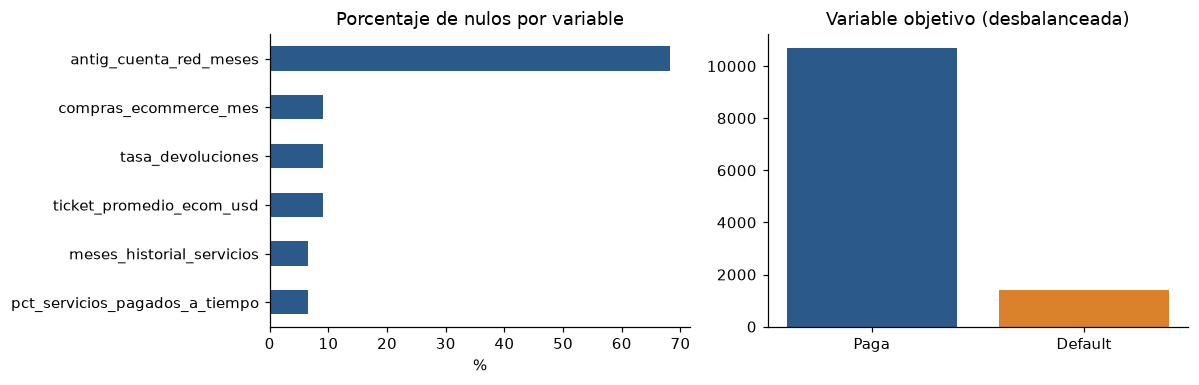

,Dimensión,Hallazgo,Registros,Decisión
0,Completitud,Nulos en servicios básicos (rezago API 24-72 h),799,Imputar mediana + indicador de faltante
1,Completitud,Nulos en e-commerce (marketplace no asociado),1103,Imputar mediana + indicador de faltante
2,Completitud,Redes sociales sin opt-in,8248,"Excluir variable (68% nulos, dato opt-in)"
3,Unicidad,Solicitudes duplicadas por reintento de API,85,drop_duplicates() por registro completo
4,Validez,Monto solicitado negativo o cero,12,Eliminar registro (no recuperable)
5,Consistencia,País escrito en mayúsculas en algunas APIs,272,Normalizar texto (str.title())
6,Atípicos,Recarga mensual sobre Q3 + 3·IQR,138,Mantener (comportamiento plausible); modelo de...
7,Balance de clases,Tasa de default = 11.6%,1396,Split estratificado + métricas AUC/recall (no ...


In [3]:
calidad = []
nulos = df.isna().mean().sort_values(ascending=False)
calidad.append(("Completitud", "Nulos en servicios básicos (rezago API 24-72 h)",
                int(df["pct_servicios_pagados_a_tiempo"].isna().sum()), "Imputar mediana + indicador de faltante"))
calidad.append(("Completitud", "Nulos en e-commerce (marketplace no asociado)",
                int(df["compras_ecommerce_mes"].isna().sum()), "Imputar mediana + indicador de faltante"))
calidad.append(("Completitud", "Redes sociales sin opt-in",
                int(df["antig_cuenta_red_meses"].isna().sum()), "Excluir variable (68% nulos, dato opt-in)"))
calidad.append(("Unicidad", "Solicitudes duplicadas por reintento de API",
                int(df.duplicated().sum()), "drop_duplicates() por registro completo"))
calidad.append(("Validez", "Monto solicitado negativo o cero",
                int((df["monto_solicitado_usd"] <= 0).sum()), "Eliminar registro (no recuperable)"))
calidad.append(("Consistencia", "País escrito en mayúsculas en algunas APIs",
                int((~df["pais"].isin(["Chile", "Peru"])).sum()), "Normalizar texto (str.title())"))
q1, q3 = df["recarga_mensual_usd"].quantile([.25, .75])
calidad.append(("Atípicos", "Recarga mensual sobre Q3 + 3·IQR",
                int((df["recarga_mensual_usd"] > q3 + 3 * (q3 - q1)).sum()), "Mantener (comportamiento plausible); modelo de árboles es robusto"))
calidad.append(("Balance de clases", f"Tasa de default = {df['default'].mean():.1%}",
                int(df["default"].sum()), "Split estratificado + métricas AUC/recall (no accuracy)"))
tabla_calidad = pd.DataFrame(calidad, columns=["Dimensión", "Hallazgo", "Registros", "Decisión"])
tabla_calidad.to_csv(OUT / "registro_calidad_datos.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
nulos[nulos > 0].mul(100).plot.barh(ax=ax[0], color=AZUL)
ax[0].set_title("Porcentaje de nulos por variable"); ax[0].set_xlabel("%"); ax[0].invert_yaxis()
ax[1].bar(["Paga", "Default"], df["default"].value_counts().sort_index(), color=[AZUL, NARANJO])
ax[1].set_title("Variable objetivo (desbalanceada)")
plt.tight_layout(); plt.savefig(FIG / "01_calidad_datos.png", bbox_inches="tight"); plt.show()
tabla_calidad

## 3. Limpieza, integración y transformación (WBS 2.3 · RF02 · RNF04)
Decisiones aplicadas:
1. Limpieza según el registro de calidad (duplicados, inválidos, formato de país).
2. **Minimización de datos (Ley 21.719, art. de proporcionalidad):** se excluyen del set de entrenamiento los atributos protegidos, los proxies socioeconómicos (gama de teléfono, NSE de comuna), los metadatos de la app (sesgo S5) y la variable de redes sociales (dato opt-in de baja cobertura). Los atributos protegidos se guardan aparte **solo para la auditoría de equidad**.
3. **Seudonimización:** el `id_solicitud` se reemplaza por un hash; el modelo nunca ve identificadores.
4. Ingeniería de variables simple: indicadores de faltante (un nulo de utilities es información, no ruido) y razón monto/ticket.
5. Split **estratificado** 70 / 15 / 15 (train / validación / test) antes de ajustar cualquier transformación, para evitar fuga de datos.

In [4]:
import hashlib
d = df.drop_duplicates().copy()
d = d[d["monto_solicitado_usd"] > 0]
d["pais"] = d["pais"].str.title()
d["id_seudo"] = d["id_solicitud"].map(lambda s: hashlib.sha256(("sal-vfg|" + s).encode()).hexdigest()[:16])
d = d.drop(columns="id_solicitud")
d["falta_servicios"] = d["pct_servicios_pagados_a_tiempo"].isna().astype(int)
d["falta_ecommerce"] = d["compras_ecommerce_mes"].isna().astype(int)
d["monto_sobre_ticket"] = d["monto_solicitado_usd"] / d["ticket_promedio_ecom_usd"]

PROTEGIDOS = ["genero", "zona", "tramo_edad", "sector_informal"]
EXCLUIDAS = ["gama_telefono", "nse_comuna", "tiempo_formulario_seg", "antig_cuenta_red_meses"]
NUM = ["antig_linea_meses", "plan_postpago", "recarga_mensual_usd", "regularidad_pago_telco",
       "pct_servicios_pagados_a_tiempo", "meses_historial_servicios", "txn_billetera_mes",
       "compras_ecommerce_mes", "ticket_promedio_ecom_usd", "tasa_devoluciones",
       "monto_solicitado_usd", "monto_sobre_ticket", "falta_servicios", "falta_ecommerce"]
CAT = ["pais"]
FEATURES = NUM + CAT

X, y, A = d[FEATURES], d["default"], d[PROTEGIDOS]
X_tmp, X_te, y_tmp, y_te, A_tmp, A_te = train_test_split(X, y, A, test_size=0.15, stratify=y, random_state=SEED)
X_tr, X_va, y_tr, y_va, A_tr, A_va = train_test_split(X_tmp, y_tmp, A_tmp, test_size=0.1765, stratify=y_tmp, random_state=SEED)
print(f"Registros limpios: {len(d):,} (eliminados {len(df) - len(d)})")
print(f"Train {len(X_tr):,} | Validación {len(X_va):,} | Test {len(X_te):,} | default train {y_tr.mean():.1%} / test {y_te.mean():.1%}")
print(f"Variables usadas por el modelo: {len(FEATURES)} | excluidas por diseño ético/legal: {len(PROTEGIDOS) + len(EXCLUIDAS)}")

Registros limpios: 11,988 (eliminados 97)
Train 8,390 | Validación 1,799 | Test 1,799 | default train 11.6% / test 11.6%
Variables usadas por el modelo: 15 | excluidas por diseño ético/legal: 8


## 4. Modelado (WBS 3.2 · RF03)
Se compara una línea base explicable con cuatro ensambles, todos dentro de un `Pipeline` de scikit-learn (las transformaciones se ajustan solo con *train*):
- **Regresión logística (base):** interpretable; referencia mínima.
- **Bagging:** árboles entrenados sobre muestras *bootstrap* (con reemplazo); reduce varianza.
- **Pasting:** el mismo esquema **sin** reemplazo; permite ver si el muestreo con reemplazo influye.
- **Random Forest:** bagging + selección aleatoria de variables en cada división.
- **Gradient Boosting:** árboles en secuencia que corrigen el error del anterior; reduce sesgo (el ensamble que describe el caso).

**Mejora respecto de la v0 del prototipo** (5.000 registros, 4 variables, una sola partición, AUC ≈ 0,66): se usa validación cruzada estratificada de 5 folds sobre *train*, un conjunto de validación para elegir el campeón y un test que se usa una sola vez.

In [5]:
prep_lineal = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
prep_arbol = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])

arbol = DecisionTreeClassifier(min_samples_leaf=10, random_state=SEED)
modelos = {
    "Regresión logística (base)": Pipeline([("prep", prep_lineal),
        ("clf", LogisticRegression(max_iter=2000, C=1.0))]),
    "Bagging (árboles)": Pipeline([("prep", prep_arbol),
        ("clf", BaggingClassifier(arbol, n_estimators=150, max_samples=0.8, bootstrap=True, random_state=SEED))]),
    "Pasting (árboles)": Pipeline([("prep", prep_arbol),
        ("clf", BaggingClassifier(arbol, n_estimators=150, max_samples=0.8, bootstrap=False, random_state=SEED))]),
    "Random Forest": Pipeline([("prep", prep_arbol),
        ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=10, random_state=SEED))]),
    "Gradient Boosting": Pipeline([("prep", prep_arbol),
        ("clf", HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_depth=4,
                                               l2_regularization=1.0, early_stopping=True,
                                               validation_fraction=0.15, random_state=SEED))]),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
res_cv = {}
for nombre, m in modelos.items():
    s = cross_val_score(m, X_tr, y_tr, cv=cv, scoring="roc_auc")
    res_cv[nombre] = s
    print(f"{nombre:28s} AUC CV = {s.mean():.3f} ± {s.std():.3f}  folds={np.round(s, 3)}")
for m in modelos.values():
    m.fit(X_tr, y_tr)

Regresión logística (base)   AUC CV = 0.820 ± 0.020  folds=[0.83  0.824 0.786 0.816 0.846]


Bagging (árboles)            AUC CV = 0.809 ± 0.020  folds=[0.82  0.81  0.778 0.801 0.837]


Pasting (árboles)            AUC CV = 0.796 ± 0.018  folds=[0.796 0.795 0.769 0.793 0.826]


Random Forest                AUC CV = 0.814 ± 0.019  folds=[0.823 0.822 0.779 0.81  0.836]


Gradient Boosting            AUC CV = 0.815 ± 0.018  folds=[0.814 0.819 0.786 0.813 0.841]


## 5. Evaluación (WBS 3.2 · criterio de aceptación)
**Criterios de aceptación acordados en el plan:** AUC ≥ 0,75 en test y mora de la cartera aprobada ≤ 9 %. El campeón se elige por AUC en **validación** entre ambos modelos: si el modelo simple rinde igual, se prefiere por ser más explicable (principio de parsimonia). El umbral de decisión se fija en **validación** (no en test) para que la cartera aprobada tenga una mora esperada ≤ 9 %, la meta del Año 2 de la Tabla 4 del caso.

AUC validación: {'Regresión logística (base)': 0.8, 'Bagging (árboles)': 0.789, 'Pasting (árboles)': 0.778, 'Random Forest': 0.793, 'Gradient Boosting': 0.787} → campeón: Regresión logística (base)
                            AUC test     KS  Brier  AUC CV (media)
Modelo                                                            
Regresión logística (base)     0.846  0.561  0.076           0.820
Bagging (árboles)              0.827  0.535  0.078           0.809
Pasting (árboles)              0.821  0.514  0.080           0.796
Random Forest                  0.835  0.538  0.077           0.814
Gradient Boosting              0.840  0.539  0.078           0.815 

{
  "auc_test": 0.846,
  "ks_test": 0.561,
  "umbral_rechazo_pd": 0.365,
  "recall_default": 0.385,
  "precision_default": 0.602,
  "f1_default": 0.469,
  "tasa_aprobacion": 0.926,
  "mora_cartera_aprobada": 0.077,
  "mora_sin_modelo": 0.116
}

CRITERIO DE ACEPTACIÓN (AUC test >= 0,75 y mora aprobada <= 9%): CUMPLE


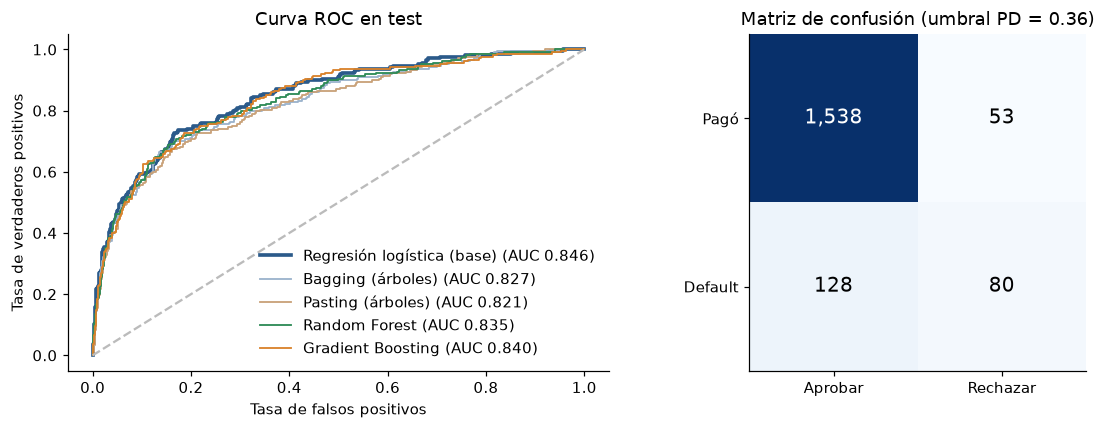

In [6]:
def ks(y_true, p):
    fpr, tpr, _ = roc_curve(y_true, p); return float(np.max(tpr - fpr))

filas = []
for nombre, m in modelos.items():
    p = m.predict_proba(X_te)[:, 1]
    filas.append({"Modelo": nombre, "AUC test": roc_auc_score(y_te, p), "KS": ks(y_te, p),
                  "Brier": brier_score_loss(y_te, p), "AUC CV (media)": res_cv[nombre].mean()})
comp = pd.DataFrame(filas).set_index("Modelo").round(3)

# Selección del campeón por AUC en VALIDACIÓN (el test se reserva para la evaluación final)
auc_va = {n: roc_auc_score(y_va, m.predict_proba(X_va)[:, 1]) for n, m in modelos.items()}
NOMBRE_CAMPEON = max(auc_va, key=auc_va.get)
campeon = modelos[NOMBRE_CAMPEON]
print("AUC validación:", {k: round(v, 3) for k, v in auc_va.items()}, "→ campeón:", NOMBRE_CAMPEON)
p_va = campeon.predict_proba(X_va)[:, 1]
p_te = campeon.predict_proba(X_te)[:, 1]

# Umbral de aprobación: el mayor que mantiene la mora de aprobados <= 9% en VALIDACIÓN
grid = np.linspace(0.02, 0.6, 117)
mora_aprob = np.array([y_va[p_va < t].mean() if (p_va < t).any() else 0 for t in grid])
UMBRAL = float(grid[mora_aprob <= 0.09].max())
pred_te = (p_te >= UMBRAL).astype(int)          # 1 = rechazar (riesgo alto)
tn, fp, fn, tp = confusion_matrix(y_te, pred_te).ravel()
aprobados = pred_te == 0
met = {
    "auc_test": round(roc_auc_score(y_te, p_te), 3), "ks_test": round(ks(y_te, p_te), 3),
    "umbral_rechazo_pd": round(UMBRAL, 3),
    "recall_default": round(recall_score(y_te, pred_te), 3),
    "precision_default": round(precision_score(y_te, pred_te), 3),
    "f1_default": round(f1_score(y_te, pred_te), 3),
    "tasa_aprobacion": round(aprobados.mean(), 3),
    "mora_cartera_aprobada": round(y_te[aprobados].mean(), 3),
    "mora_sin_modelo": round(y_te.mean(), 3),
}
print(comp, "\n")
print(json.dumps(met, indent=2, ensure_ascii=False))
met["modelo_campeon"] = NOMBRE_CAMPEON
cumple = met["auc_test"] >= 0.75 and met["mora_cartera_aprobada"] <= 0.09
print("\nCRITERIO DE ACEPTACIÓN (AUC test >= 0,75 y mora aprobada <= 9%):", "CUMPLE" if cumple else "NO CUMPLE")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for (nombre, m), c in zip(modelos.items(), [AZUL, "#9bb3cc", "#c9a27a", VERDE, NARANJO]):
    fpr, tpr, _ = roc_curve(y_te, m.predict_proba(X_te)[:, 1])
    ax[0].plot(fpr, tpr, color=c, lw=2.4 if nombre == NOMBRE_CAMPEON else 1.2,
               label=f"{nombre} (AUC {roc_auc_score(y_te, m.predict_proba(X_te)[:, 1]):.3f})")
ax[0].plot([0, 1], [0, 1], ls="--", color="#bbb"); ax[0].set_xlabel("Tasa de falsos positivos"); ax[0].set_ylabel("Tasa de verdaderos positivos")
ax[0].set_title("Curva ROC en test"); ax[0].legend(loc="lower right", frameon=False)
cm = np.array([[tn, fp], [fn, tp]])
ax[1].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[1].text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=13, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax[1].set_xticks([0, 1], ["Aprobar", "Rechazar"]); ax[1].set_yticks([0, 1], ["Pagó", "Default"])
ax[1].set_title(f"Matriz de confusión (umbral PD = {UMBRAL:.2f})")
plt.tight_layout(); plt.savefig(FIG / "02_roc_confusion.png", bbox_inches="tight"); plt.show()

**Lectura para negocio:** sin modelo, VFG aprobaría a todos con la mora de la población (≈ 11 %). Con el umbral elegido, el motor aprueba a la mayoría de los solicitantes y la mora de la cartera aprobada baja a la meta del Año 2. Es decir, el modelo **amplía el acceso con riesgo controlado**, que es el objetivo del proyecto.

## 6. Explicabilidad (WBS 4.2 · RF05 · "derecho a explicación")
- **Global:** importancia por permutación en test (cuánto cae el AUC si se desordena cada variable).
- **Individual (reason codes):** para cada solicitante se mide cuánto baja su probabilidad de default si una variable toma el valor típico de un buen pagador. Las 3 variables que más suben el riesgo se comunican al solicitante rechazado en lenguaje simple.

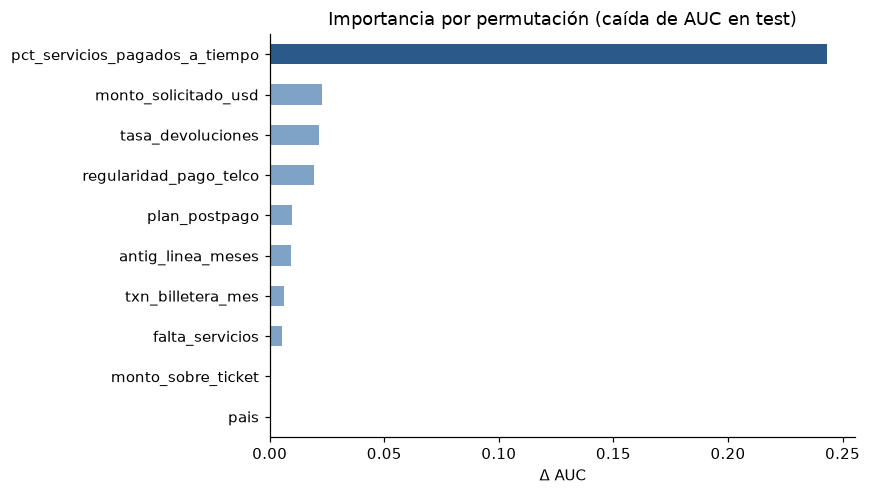

Solicitante de mayor riesgo en test: PD = 0.93
  · pago puntual de cuentas de servicios básicos: +0.74 de probabilidad de default
  · regularidad de pago del plan móvil: +0.08 de probabilidad de default
  · devoluciones en compras online: +0.05 de probabilidad de default


In [7]:
imp = permutation_importance(campeon, X_te, y_te, scoring="roc_auc", n_repeats=8, random_state=SEED)
imp_s = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.6))
imp_s.tail(10).plot.barh(ax=ax, color=[AZUL if v == imp_s.max() else "#7fa3c7" for v in imp_s.tail(10)])
ax.set_title("Importancia por permutación (caída de AUC en test)"); ax.set_xlabel("Δ AUC")
plt.tight_layout(); plt.savefig(FIG / "03_importancia.png", bbox_inches="tight"); plt.show()

ETIQUETAS = {
    "pct_servicios_pagados_a_tiempo": "pago puntual de cuentas de servicios básicos",
    "regularidad_pago_telco": "regularidad de pago del plan móvil",
    "antig_linea_meses": "antigüedad de la línea móvil",
    "txn_billetera_mes": "movimientos en billetera digital",
    "tasa_devoluciones": "devoluciones en compras online",
    "monto_solicitado_usd": "monto solicitado",
    "monto_sobre_ticket": "monto solicitado respecto de su gasto habitual",
    "plan_postpago": "tipo de plan móvil",
    "meses_historial_servicios": "historial con empresas de servicios",
    "compras_ecommerce_mes": "frecuencia de compras online",
    "ticket_promedio_ecom_usd": "gasto promedio en compras online",
    "recarga_mensual_usd": "recarga mensual de saldo",
    "falta_servicios": "falta de información de servicios básicos",
    "falta_ecommerce": "falta de información de compras online",
}
REF = X_tr[y_tr == 0][NUM].median()

def reason_codes(fila: pd.DataFrame, k=3):
    base = campeon.predict_proba(fila)[:, 1][0]
    variantes = pd.concat([fila] * len(NUM), ignore_index=True)
    for i, c in enumerate(NUM):
        variantes.loc[i, c] = REF[c]
    deltas = base - campeon.predict_proba(variantes)[:, 1]
    top = pd.Series(deltas, index=NUM).sort_values(ascending=False).head(k)
    return [(ETIQUETAS[c], round(float(v), 3)) for c, v in top.items() if v > 0]

ejemplo = X_te.iloc[[int(np.argmax(p_te))]]
print(f"Solicitante de mayor riesgo en test: PD = {p_te.max():.2f}")
for et, v in reason_codes(ejemplo):
    print(f"  · {et}: +{v:.2f} de probabilidad de default")

## 7. Auditoría de equidad (WBS 4.2 · RNF08 · medidas M2 y M3 de la EP1)
Se comparan, por grupo protegido, la **tasa de aprobación** y la **paridad de oportunidad** (tasa de aprobación entre quienes efectivamente pagaron). Regla operativa acordada: razón entre el grupo menos favorecido y el más favorecido **≥ 0,80** (regla de los 4/5). Los atributos protegidos no entran al modelo; aun así, la brecha puede aparecer por la huella digital menor de algunos grupos (sesgo S3, "exclusión digital inversa").

,atributo,grupo,n,tasa_aprobacion,aprob_buenos_pagadores,mora_real
0,genero,F,702.0,0.917,0.969,0.125
1,genero,M,1097.0,0.932,0.965,0.109
2,zona,rural,290.0,0.897,0.960,0.145
3,zona,urbana,1509.0,0.932,0.968,0.110
4,tramo_edad,18-24,84.0,0.881,0.941,0.190
5,tramo_edad,25-45,1424.0,0.933,0.969,0.110
6,tramo_edad,46-60,208.0,0.889,0.950,0.130
7,tramo_edad,60+,83.0,0.940,0.987,0.096
8,sector_informal,0,1231.0,0.925,0.968,0.115
9,sector_informal,1,568.0,0.928,0.964,0.116


,ratio_aprobacion,ratio_oportunidad,cumple_4/5
atributo,,,
genero,0.985,0.996,True
sector_informal,0.997,0.996,True
tramo_edad,0.937,0.954,True
zona,0.962,0.991,True


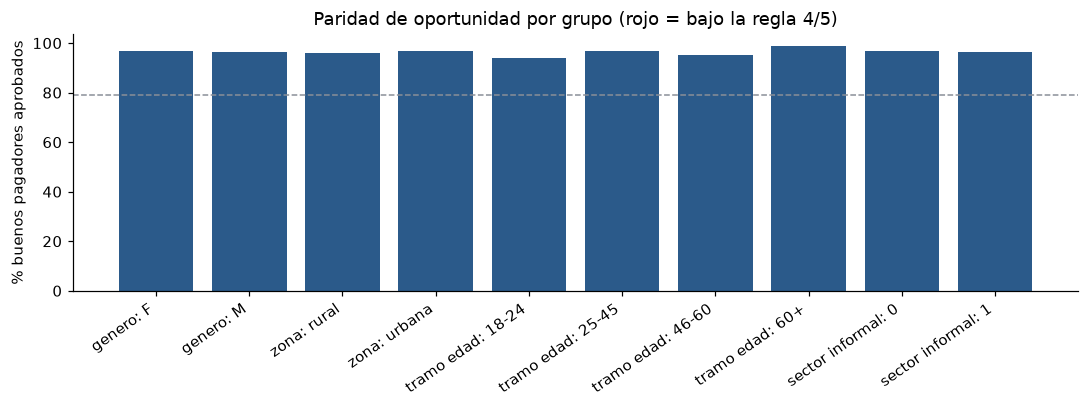

In [8]:
aud = A_te.copy()
aud["aprobado"] = aprobados.astype(int); aud["pago"] = (y_te.values == 0).astype(int)
filas = []
for g in PROTEGIDOS:
    t = aud.groupby(g).agg(n=("aprobado", "size"), tasa_aprobacion=("aprobado", "mean"))
    t["aprob_buenos_pagadores"] = aud[aud["pago"] == 1].groupby(g)["aprobado"].mean()
    t["mora_real"] = 1 - aud.groupby(g)["pago"].mean()
    for nivel, r in t.iterrows():
        filas.append({"atributo": g, "grupo": str(nivel), **r.to_dict()})
equidad = pd.DataFrame(filas)
ratios = (equidad.groupby("atributo")
          .agg(ratio_aprobacion=("tasa_aprobacion", lambda s: s.min() / s.max()),
               ratio_oportunidad=("aprob_buenos_pagadores", lambda s: s.min() / s.max())))
ratios["cumple_4/5"] = (ratios[["ratio_aprobacion", "ratio_oportunidad"]] >= 0.80).all(axis=1)
equidad.round(3).to_csv(OUT / "auditoria_equidad.csv", index=False)
display(equidad.round(3))
display(ratios.round(3))

fig, ax = plt.subplots(figsize=(10, 3.8))
lab = equidad["atributo"].str.replace("_", " ") + ": " + equidad["grupo"]
cols = [ROJO if (equidad.loc[i, "aprob_buenos_pagadores"] / equidad[equidad.atributo == equidad.loc[i, "atributo"]]["aprob_buenos_pagadores"].max()) < 0.8 else AZUL for i in equidad.index]
ax.bar(lab, equidad["aprob_buenos_pagadores"] * 100, color=cols)
ax.axhline(equidad["aprob_buenos_pagadores"].max() * 80, ls="--", color=GRIS, lw=1)
ax.set_ylabel("% buenos pagadores aprobados"); ax.set_title("Paridad de oportunidad por grupo (rojo = bajo la regla 4/5)")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.savefig(FIG / "04_equidad.png", bbox_inches="tight"); plt.show()

## 8. Motor de decisión (WBS 3.3 · RF04 · revisión humana M5)
El motor convierte la probabilidad de default (PD) en una de tres decisiones. La zona intermedia **no se automatiza**: se deriva a un analista, para cumplir el derecho a revisión humana en decisiones automatizadas de alto impacto (Ley 21.719 y medidas M4/M5 de la EP1).

| PD | Decisión | Acción |
|---|---|---|
| < umbral | APROBAR | crédito automático |
| entre umbral y umbral + 0,10 | REVISIÓN HUMANA | analista de riesgo decide (con reason codes) |
| > umbral + 0,10 | RECHAZAR | se comunican los 3 factores principales y el canal de apelación |

In [9]:
BANDA_BAJA, BANDA_ALTA = UMBRAL, UMBRAL + 0.10

def motor_decision(solicitud: dict) -> dict:
    fila = pd.DataFrame([solicitud])[FEATURES]
    pd_ = float(campeon.predict_proba(fila)[:, 1][0])
    if pd_ < BANDA_BAJA:
        decision = "APROBAR"
    elif pd_ <= BANDA_ALTA:
        decision = "REVISION_HUMANA"
    else:
        decision = "RECHAZAR"
    salida = {"pd": round(pd_, 3), "score": int(round(1000 * (1 - pd_))), "decision": decision}
    if decision != "APROBAR":
        salida["factores"] = [e for e, _ in reason_codes(fila)]
    return salida

dist = pd.Series([motor_decision(r) ["decision"] for r in X_te.to_dict("records")]).value_counts(normalize=True)
print("Distribución de decisiones en test:\n", dist.round(3).to_string())
print("\nEjemplo de respuesta del motor:")
print(json.dumps(motor_decision(X_te.iloc[int(np.argmax(p_te))].to_dict()), indent=2, ensure_ascii=False))

Distribución de decisiones en test:
 APROBAR            0.926
RECHAZAR           0.048
REVISION_HUMANA    0.026

Ejemplo de respuesta del motor:
{
  "pd": 0.927,
  "score": 73,
  "decision": "RECHAZAR",
  "factores": [
    "pago puntual de cuentas de servicios básicos",
    "regularidad de pago del plan móvil",
    "devoluciones en compras online"
  ]
}


## 9. Prueba de rendimiento (WBS 4.1 · RNF01: respuesta < 8 s)
Se mide la latencia de 500 solicitudes individuales de punta a punta (PD + decisión + reason codes) en un notebook local. Es una prueba unitaria del motor; la prueba de carga a 2.400 millones de eventos/mes se hará en el ambiente cloud (Alternativa A) y queda registrada como tarea pendiente.

In [10]:
muestras = X_te.sample(500, random_state=SEED).to_dict("records")
lat = []
for r in muestras:
    t0 = time.perf_counter(); motor_decision(r); lat.append((time.perf_counter() - t0) * 1000)
lat = np.array(lat)
latencia = {"p50_ms": round(float(np.percentile(lat, 50)), 1), "p95_ms": round(float(np.percentile(lat, 95)), 1),
            "max_ms": round(float(lat.max()), 1), "objetivo_ms": 8000}
print(latencia, "→", "CUMPLE RNF01" if latencia["p95_ms"] < 8000 else "NO CUMPLE")

{'p50_ms': 4.1, 'p95_ms': 12.9, 'max_ms': 17.8, 'objetivo_ms': 8000} → CUMPLE RNF01


## 10. Monitoreo de drift (WBS 5.2 · RNF07)
Se simula el primer mes de operación de una nueva cohorte con más usuarios prepago y menor huella digital (situación esperable al expandirse a Colombia y México) y se calcula el **Population Stability Index (PSI)** por variable. Umbrales: < 0,10 estable · 0,10–0,25 investigar · ≥ 0,25 reentrenar.

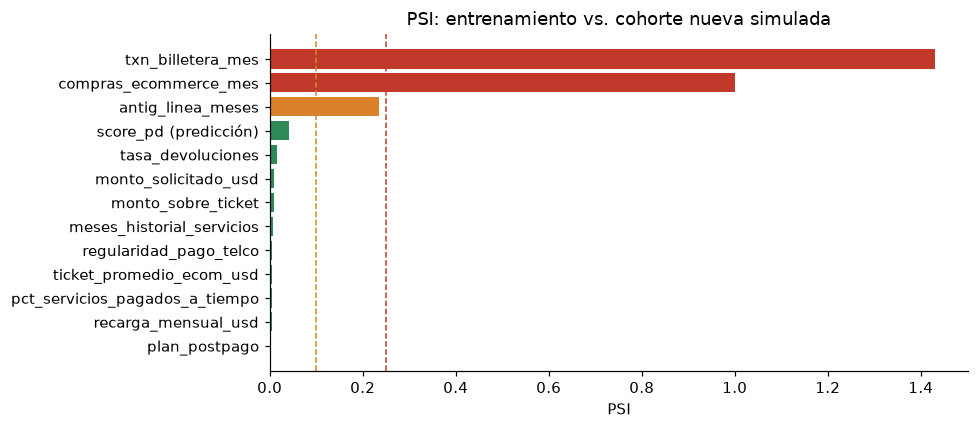

,PSI,estado
txn_billetera_mes,1.430,REENTRENAR
compras_ecommerce_mes,1.001,REENTRENAR
antig_linea_meses,0.236,INVESTIGAR
score_pd (predicción),0.042,ESTABLE
tasa_devoluciones,0.015,ESTABLE
monto_solicitado_usd,0.010,ESTABLE
monto_sobre_ticket,0.009,ESTABLE
meses_historial_servicios,0.008,ESTABLE
regularidad_pago_telco,0.006,ESTABLE
ticket_promedio_ecom_usd,0.006,ESTABLE


In [11]:
def psi(esperado, actual, bins=10):
    esperado, actual = pd.Series(esperado).dropna(), pd.Series(actual).dropna()
    cortes = np.unique(np.quantile(esperado, np.linspace(0, 1, bins + 1)))
    e = np.histogram(esperado, cortes)[0] / len(esperado) + 1e-4
    a = np.histogram(np.clip(actual, cortes[0], cortes[-1]), cortes)[0] / len(actual) + 1e-4
    return float(np.sum((a - e) * np.log(a / e)))

nuevo = X_te.copy()
nuevo["plan_postpago"] = (rng.random(len(nuevo)) < 0.22).astype(int)
nuevo["txn_billetera_mes"] = (nuevo["txn_billetera_mes"] * 0.7).round()
nuevo["compras_ecommerce_mes"] = (nuevo["compras_ecommerce_mes"] * 0.6).round()
nuevo["antig_linea_meses"] = nuevo["antig_linea_meses"] * rng.uniform(0.6, 1.0, len(nuevo))
tabla_psi = pd.Series({c: psi(X_tr[c], nuevo[c]) for c in NUM if c not in ("falta_servicios", "falta_ecommerce")})
tabla_psi["score_pd (predicción)"] = psi(campeon.predict_proba(X_tr)[:, 1], campeon.predict_proba(nuevo)[:, 1])
tabla_psi = tabla_psi.sort_values(ascending=False).round(3)
estado = tabla_psi.map(lambda v: "REENTRENAR" if v >= .25 else ("INVESTIGAR" if v >= .10 else "ESTABLE"))
monitoreo = pd.DataFrame({"PSI": tabla_psi, "estado": estado})
monitoreo.to_csv(OUT / "monitoreo_psi.csv")

fig, ax = plt.subplots(figsize=(9, 4))
colores = monitoreo["estado"].map({"REENTRENAR": ROJO, "INVESTIGAR": NARANJO, "ESTABLE": VERDE})
ax.barh(monitoreo.index, monitoreo["PSI"], color=colores); ax.invert_yaxis()
for x, c in [(0.10, NARANJO), (0.25, ROJO)]:
    ax.axvline(x, ls="--", color=c, lw=1)
ax.set_title("PSI: entrenamiento vs. cohorte nueva simulada"); ax.set_xlabel("PSI")
plt.tight_layout(); plt.savefig(FIG / "05_drift_psi.png", bbox_inches="tight"); plt.show()
monitoreo

## 11. Artefactos versionados (WBS 5.2)
Se serializa el pipeline completo (preparación + modelo) y se genera una **model card** (Mitchell et al., 2019) con uso previsto, métricas, equidad y limitaciones. Estos archivos quedan en `outputs/` del repositorio.

In [12]:
joblib.dump(campeon, OUT / "aurora_score_v1.joblib")
model_card = {
    "modelo": "AURORA SCORE v1 (prototipo)", "fecha": pd.Timestamp.today().strftime("%Y-%m-%d"),
    "algoritmo": NOMBRE_CAMPEON + " (scikit-learn Pipeline con imputación)", "auc_validacion": {k: round(v, 3) for k, v in auc_va.items()},
    "uso_previsto": "Apoyo a la decisión de microcréditos para solicitantes sin historial bancario (piloto Chile/Perú)",
    "uso_no_previsto": "Decisión 100% automática en zona gris; uso fuera de Chile/Perú sin recalibración",
    "datos": f"Dataset sintético que replica el piloto ({len(d):,} solicitudes limpias)",
    "variables_modelo": FEATURES, "variables_excluidas": PROTEGIDOS + EXCLUIDAS,
    "metricas_test": met, "auc_cv_media": round(float(res_cv[NOMBRE_CAMPEON].mean()), 3),
    "latencia": latencia,
    "equidad_ratios": ratios.round(3).reset_index().to_dict("records"),
    "drift_variables_reentrenar": monitoreo.index[monitoreo["estado"] == "REENTRENAR"].tolist(),
    "limitaciones": ["Datos sintéticos: métricas deben recalcularse con la cartera real del piloto",
                     "Sesgo de selección: solo se observa el pago de quienes fueron aprobados (S4)",
                     "Prueba de latencia local; falta prueba de carga en la nube"],
    "versiones": {"python_sklearn": sklearn.__version__, "pandas": pd.__version__, "semilla": SEED},
}
(OUT / "model_card.json").write_text(json.dumps(model_card, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
(OUT / "metricas.json").write_text(json.dumps({"comparacion": comp.reset_index().to_dict("records"), **met,
                                               "latencia": latencia}, indent=2, ensure_ascii=False), encoding="utf-8")
print("Artefactos generados:")
for p in sorted(OUT.rglob("*")):
    if p.is_file():
        print("  ", p.as_posix(), f"({p.stat().st_size / 1024:.0f} KB)")

Artefactos generados:
   outputs/auditoria_equidad.csv (0 KB)
   outputs/aurora_score_v1.joblib (5 KB)
   outputs/figs/01_calidad_datos.png (30 KB)
   outputs/figs/02_roc_confusion.png (61 KB)
   outputs/figs/03_importancia.png (29 KB)
   outputs/figs/04_equidad.png (38 KB)
   outputs/figs/05_drift_psi.png (38 KB)
   outputs/metricas.json (1 KB)
   outputs/model_card.json (3 KB)
   outputs/monitoreo_psi.csv (0 KB)
   outputs/registro_calidad_datos.csv (1 KB)


## 12. Resumen de resultados parciales

In [13]:
print(f'''
RESUMEN DEL PROTOTIPO AURORA SCORE v1
- Datos: {len(d):,} solicitudes limpias ({len(df) - len(d)} eliminadas por calidad); {len(FEATURES)} variables; {len(PROTEGIDOS) + len(EXCLUIDAS)} excluidas por diseño.
- Modelo campeón: {NOMBRE_CAMPEON} | AUC test {met["auc_test"]} | KS {met["ks_test"]} | comparación: {comp["AUC test"].to_dict()}.
- Negocio: aprueba {met["tasa_aprobacion"]:.0%} de los solicitantes con mora de cartera {met["mora_cartera_aprobada"]:.1%} (vs {met["mora_sin_modelo"]:.1%} sin modelo).
- Motor: aprobar / revisión humana / rechazar con reason codes; latencia p95 {latencia["p95_ms"]} ms (objetivo < 8.000 ms).
- Equidad: atributos que no cumplen la regla 4/5 → {ratios.index[~ratios["cumple_4/5"]].tolist() or "ninguno"}.
- Drift simulado: reentrenar si se expande sin recalibrar → {monitoreo.index[monitoreo["estado"] == "REENTRENAR"].tolist()}.
''')


RESUMEN DEL PROTOTIPO AURORA SCORE v1
- Datos: 11,988 solicitudes limpias (97 eliminadas por calidad); 15 variables; 8 excluidas por diseño.
- Modelo campeón: Regresión logística (base) | AUC test 0.846 | KS 0.561 | comparación: {'Regresión logística (base)': 0.846, 'Bagging (árboles)': 0.827, 'Pasting (árboles)': 0.821, 'Random Forest': 0.835, 'Gradient Boosting': 0.84}.
- Negocio: aprueba 93% de los solicitantes con mora de cartera 7.7% (vs 11.6% sin modelo).
- Motor: aprobar / revisión humana / rechazar con reason codes; latencia p95 12.9 ms (objetivo < 8.000 ms).
- Equidad: atributos que no cumplen la regla 4/5 → ninguno.
- Drift simulado: reentrenar si se expande sin recalibrar → ['txn_billetera_mes', 'compras_ecommerce_mes'].

